# Healthcare Analytics & Operational Insights

This project explores admission records, length of stay, recorded billing and test-result distributions in a synthetic healthcare dataset. It also evaluates whether simple forecasting and admission-time predictive methods improve on baseline models.


## Healthcare Dataset — Brief Summary

**Source:** Kaggle — *Healthcare Dataset*  
**Link:** [Healthcare dataset input page](https://www.kaggle.com/code/manarmohamed24/analysis-healthcare-dataset/input)  
**Dataset type:** Synthetic healthcare records  
**Original dimensions:** 55,500 rows and 15 columns  
**Granularity:** One row represents a synthetic admission record, not a verified unique patient.

The dataset supports exploratory analysis of recorded demographics, conditions, admissions, stay duration, billing, insurance, medications, and test-result categories.

**Version note:** The original analysis retained 54,860 records after removing 534 exact duplicates and 106 negative-billing records. The revised approach retains otherwise valid negative-billing records for operational analysis and checks for additional duplicates after text standardisation. Revised population counts must therefore be calculated from the executed cleaning pipeline.

**Licence note:** Verify the original dataset’s licence before redistributing its data. Synthetic status does not establish educational-only or non-commercial licence terms.

## Original Columns

| Column | Description and analytical limitation |
|---|---|
| Name | Synthetic name with inconsistent casing; not a reliable patient identifier |
| Age | Recorded age in years; validate numeric values and plausible ranges |
| Gender | Recorded category, including Male and Female |
| Blood Type | A+, A-, B+, B-, AB+, AB-, O+, O-; preserve uppercase labels |
| Medical Condition | Recorded condition: Arthritis, Diabetes, Cancer, Obesity, Hypertension, or Asthma |
| Date of Admission | Recorded admission date |
| Doctor | Synthetic doctor label; not a verified provider identifier |
| Hospital | Synthetic hospital label; not a verified facility identifier |
| Insurance Provider | Recorded insurer category, including Cigna, Medicare, Aetna, Blue Cross, and UnitedHealthcare |
| Billing Amount | Recorded numeric amount; currency, payment status, and cost meaning are not verified |
| Room Number | Room label within a hospital; not a measure of room quality, severity, or bed capacity |
| Admission Type | Elective, Urgent, or Emergency |
| Discharge Date | Recorded discharge date; validate against admission date |
| Medication | Recorded medication label; no dosage, duration, consumption, or treatment-effect information |
| Test Results | Normal, Abnormal, or Inconclusive; does not establish recovery |

## Coverage and Preliminary Profile

The following ranges were reported in the original profiling material. Confirm them against the loaded source file before using them as final revised results.

| Field | Reported coverage or range |
|---|---|
| Age | Approximately 13–89 years |
| Date of Admission | 2019-05-08 to 2024-05-07 |
| Discharge Date | 2019-05-09 to 2024-06-06 |
| Billing Amount | Approximately -2,008.49 to 52,764.28 |
| Room Number | 101–500 |

The original analysis showed approximately balanced gender categories and relatively even distributions across conditions, admission types, insurers, medications, and test-result categories.

Exact counts and percentages depend on the analytical population. Recalculate them after revised cleaning rather than copying percentages from the previous version or profiling charts that combine categories into “Other.”

## Data Quality and Cleaning Decisions

- Preserve the original dataset separately from transformed analytical tables.
- Remove exact duplicate copies under a documented record-level assumption.
- After standardising text, check for additional exact duplicates across all original fields. Do not deduplicate on Name alone.
- Trim whitespace and standardise categorical labels. Preserve uppercase blood types such as `AB+`.
- Do not merge hospital or doctor labels merely by rearranging words or removing meaningful text.
- Parse admission and discharge dates, checking for missing dates and discharge dates before admission.
- Validate age values and document records excluded or quarantined.
- Investigate negative billing without assuming it represents refunds, errors, or adjustments.
- Retain otherwise valid negative-billing records for demographic, admission, and stay analyses.
- Use a separately defined nonnegative-billing population for financial summaries and disclose its exclusions.
- Treat generated `RecordID` values as row identifiers, not patient identifiers.

## Analytical Populations

| Population | Inclusion rule | Main uses |
|---|---|---|
| Raw dataset | All original source records | Profiling and traceability |
| Operational population | Deduplicated records with valid age and admission/discharge dates, regardless of billing sign | Demographics, admission patterns, stay duration, and test-result distributions |
| Financial population | Operational records with nonmissing Billing Amount ≥ 0 | Nonnegative recorded billing summaries |
| Quarantined records | Records failing documented age or date validation | Data-quality investigation |

Negative billing is excluded from financial metrics, not automatically from admission counts. Nonnegative recorded billing must not be labelled net revenue, payments received, or healthcare cost.

## Derived Features

| Feature | Definition and interpretation |
|---|---|
| RecordID | Generated identifier for an admission record |
| LOS_Days | Discharge Date minus Date of Admission, expressed in days |
| AgeGroup | Inclusive bands: 0–18, 19–35, 36–50, 51–65, and 66+ |
| AdmissionMonth | Chronological year-month for admission analysis |
| BillingEligible | Indicates a nonmissing, nonnegative recorded billing amount |
| NegativeBilling | Flags records with Billing Amount < 0 |
| BillingBand | Documented descriptive billing thresholds |
| HighBillingDescriptive | Billing above the financial population’s 75th percentile; a retrospective flag, not predicted risk |

For predictive experiments, calculate the high-billing threshold using training data only and apply that fixed threshold to validation and test records. Keep it distinct from the full-population descriptive flag.

## Analysis and Interpretation Notes

- **Record counts:** Describe admission records, not verified unique patients. Repeated names do not establish repeat admissions.
- **Age comparisons:** Use correctly labelled age bands and compare within-band percentages alongside counts. Unequal band widths affect totals.
- **Time comparisons:** Flag incomplete boundary months and account for observed days before interpreting peaks or seasonality.
- **Provider comparisons:** Hospital and doctor labels have high cardinality and often sparse counts. Caseload rankings do not establish provider quality.
- **Test results:** Report Normal Test Result Share, not recovery rate.
- **Medication analysis:** Describe recorded frequencies only; do not infer treatment efficacy or prescribing recommendations.
- **Room analysis:** Scope room labels to hospitals. Numeric room order does not establish an outcome relationship.
- **Resource analysis:** Record counts and stay-days are illustrative workload proxies, not direct measures of staffing, bed utilisation, or medication requirements.
- **Predictive analysis:** Use chronological evaluation, admission-time features, and simple baseline comparisons. Report weak or absent predictive improvement honestly.
- **Forecast timing:** Projections begin from the historical dataset cutoff, not the current date.

## Limitations

This is a synthetic-data analytical exercise. Findings cannot establish real-world disease prevalence, clinical risk, treatment effectiveness, hospital performance, or operational requirements.

The dataset does not supply a verified patient identifier, clinical recovery outcome, department field, bed capacity, staffing requirement, or medication-consumption measure. Questions requiring those variables must be documented as unsupported rather than answered through assumptions.

In [1]:
from pathlib import Path
import hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression, LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             precision_score, recall_score)
from IPython.display import display

BASE = Path('..')
RAW_PATH = BASE / 'data/raw/healthcare_dataset.csv'
OUT = BASE / 'data/processed'
FIG = BASE / 'figures'
DOC = BASE / 'docs'
for folder in [OUT, FIG, DOC]: folder.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
SEED = 42

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()

if not RAW_PATH.exists():
    raise FileNotFoundError(f'Place your source CSV at {RAW_PATH.resolve()}')
raw_bytes = RAW_PATH.read_bytes()
df = pd.read_csv(RAW_PATH)
source_manifest = {'file': RAW_PATH.name, 'sha256': hashlib.sha256(raw_bytes).hexdigest(),
                   'raw_rows': len(df), 'python': platform.python_version(),
                   'source_version': 'Record the downloaded Kaggle version manually',
                   'licence': 'Verify on the original dataset page before redistribution'}
print('Raw shape:', df.shape)
display(df.head())

Raw shape: (55500, 15)


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [2]:
# Initial Inspection of the dataset
print("Dataset Shape:", df.shape) # print the shape of the dataset
print("\nColumns in the dataset:") # print the columns in the dataset
print(df.columns.tolist())
print("\nData Types:") # print the data types of the columns
print(df.dtypes)


Dataset Shape: (55500, 15)

Columns in the dataset:
['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition', 'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider', 'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date', 'Medication', 'Test Results']

Data Types:
Name                   object
Age                     int64
Gender                 object
Blood Type             object
Medical Condition      object
Date of Admission      object
Doctor                 object
Hospital               object
Insurance Provider     object
Billing Amount        float64
Room Number             int64
Admission Type         object
Discharge Date         object
Medication             object
Test Results           object
dtype: object


In [3]:
# Checking for missing values, distinct, and duplicate values in the dataset
required = ['Name','Age','Gender','Blood Type','Medical Condition','Date of Admission',
            'Doctor','Hospital','Insurance Provider','Billing Amount','Room Number',
            'Admission Type','Discharge Date','Medication','Test Results']
assert set(required).issubset(df.columns), 'Source schema differs; investigate before proceeding.'
quality = pd.DataFrame({'dtype': df.dtypes.astype(str),
                        'missing': df.isna().sum(),
                        'missing_pct': df.isna().mean()*100,
                        'distinct': df.nunique()})
display(quality)
display(df[['Age','Billing Amount','Room Number']].describe())
print('Exact raw duplicate copies:', df.duplicated().sum())

,dtype,missing,missing_pct,distinct
Name,object,0,0.0,49992
Age,int64,0,0.0,77
Gender,object,0,0.0,2
Blood Type,object,0,0.0,8
Medical Condition,object,0,0.0,6
Date of Admission,object,0,0.0,1827
Doctor,object,0,0.0,40341
Hospital,object,0,0.0,39876
Insurance Provider,object,0,0.0,5
Billing Amount,float64,0,0.0,50000


,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


Exact raw duplicate copies: 534


## Cleaning decisions
Preserve raw data. Remove exact duplicate copies as an explicit record-level assumption. Standardise whitespace/case, then check for additional exact duplicates across all original fields. Do not deduplicate on Name alone or merge providers by rearranging name words.

Retain negative-billing records for demographic/admission/stay analysis if the record is otherwise valid. Their admission does not disappear merely because the amount is anomalous. Separate a nonnegative-billing view for financial summaries and disclose excluded counts/amounts; negative values are not automatically errors or refunds.

Use uppercase blood types (AB+, not Ab+). Retain missing/unrecognised categories as quality flags. RecordID is a generated row identifier, not a patient ID.

In [4]:
raw_duplicate_copies = int(df.duplicated().sum())
base = df.drop_duplicates().copy()
for col in ['Name','Gender','Blood Type','Medical Condition','Doctor','Hospital',
            'Insurance Provider','Admission Type','Medication','Test Results']:
    base[col] = base[col].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True).str.upper()
    base[col] = base[col].replace('', pd.NA)
for col in ['Date of Admission','Discharge Date']:
    base[col] = pd.to_datetime(base[col], format='%Y-%m-%d', errors='coerce')
for col in ['Age','Billing Amount','Room Number']:
    base[col] = pd.to_numeric(base[col], errors='coerce')
normalised_duplicate_copies = int(base.duplicated(subset=required).sum())
base = base.drop_duplicates(subset=required).copy()
base['RecordID'] = 'R' + (base.index + 1).astype(str).str.zfill(6)
base['LOS_Days'] = (base['Discharge Date'] - base['Date of Admission']).dt.days
base['InvalidDate'] = (base['Date of Admission'].isna() | base['Discharge Date'].isna()
                       | base['LOS_Days'].lt(0))
base['InvalidAge'] = (base['Age'].isna() | base['Age'].lt(0) | base['Age'].gt(120)
                      | base['Age'].mod(1).ne(0))
base['NegativeBilling'] = base['Billing Amount'].lt(0)
base['MissingBilling'] = base['Billing Amount'].isna()
allowed = {'Gender': {'MALE','FEMALE'},
           'Blood Type': {'A+','A-','B+','B-','AB+','AB-','O+','O-'},
           'Admission Type': {'ELECTIVE','URGENT','EMERGENCY'},
           'Test Results': {'NORMAL','ABNORMAL','INCONCLUSIVE'}}
for col, valid in allowed.items():
    print(col, 'unexpected/missing labels:', (~base[col].isin(valid)).sum())
audit = pd.Series({'Raw records': len(df), 'Raw duplicate copies removed': raw_duplicate_copies,
                   'Additional normalised duplicate copies removed': normalised_duplicate_copies,
                   'Post-deduplication records': len(base), 'Invalid date records': base['InvalidDate'].sum(),
                   'Invalid age records': base['InvalidAge'].sum(),
                   'Negative billing records': base['NegativeBilling'].sum(),
                   'Missing billing records': base['MissingBilling'].sum()})
display(audit.to_frame('Count'))
audit.to_csv(OUT/'cleaning_audit.csv', header=['Count'])

Gender unexpected/missing labels: 0
Blood Type unexpected/missing labels: 0
Admission Type unexpected/missing labels: 0
Test Results unexpected/missing labels: 0


,Count
Raw records,55500
Raw duplicate copies removed,534
Additional normalised duplicate copies removed,0
Post-deduplication records,54966
Invalid date records,0
Invalid age records,0
Negative billing records,106
Missing billing records,0


## Analytical populations and corrected age groups
Operational summaries include records with valid dates and age, regardless of billing sign. Quarantined records are counted separately. Financial summaries below use nonnegative recorded amounts and are labelled accordingly.

Age bands are inclusive at the printed endpoints: 0-18, 19-35, 36-50, 51-65 and 66+. They are analytical bands, not assertions about clinical definitions of senior/geriatric age. The original `right=False` code incorrectly put age 18 in “19-35” and age 65 in “66+.”

In [5]:
quarantine = base.loc[base['InvalidDate'] | base['InvalidAge']].copy()
ops = base.loc[~base['InvalidDate'] & ~base['InvalidAge']].copy()
ops['AgeGroup'] = pd.cut(ops['Age'], bins=[-1,18,35,50,65,120],
                         labels=['0-18','19-35','36-50','51-65','66+'], right=True)
ops['AdmissionMonth'] = ops['Date of Admission'].dt.to_period('M').astype(str)
ops['AdmissionDate'] = ops['Date of Admission'].dt.normalize()
ops['DischargeDate'] = ops['Discharge Date'].dt.normalize()
ops['BillingEligible'] = (~ops['MissingBilling'] & ~ops['NegativeBilling'])
finance = ops.loc[ops['BillingEligible']].copy()
threshold_descriptive = finance['Billing Amount'].quantile(.75)
ops['HighBillingDescriptive'] = pd.Series(pd.NA, index=ops.index, dtype='boolean')
ops.loc[finance.index,'HighBillingDescriptive'] = finance['Billing Amount'].gt(threshold_descriptive)
ops['BillingBand'] = 'EXCLUDED / MISSING'
ops.loc[finance.index,'BillingBand'] = pd.cut(finance['Billing Amount'],
    bins=[-np.inf,5000,15000,30000,np.inf], labels=['UP TO 5K','5K-15K','15K-30K','OVER 30K'],
    right=True).astype('string')
assert ops['RecordID'].is_unique and ops['AgeGroup'].notna().all()
print('Operational records:', len(ops), 'Financial records:', len(finance), 'Quarantine:', len(quarantine))
print('Dates:', ops['AdmissionDate'].min(), 'to', ops['AdmissionDate'].max())
print('Descriptive high-billing threshold:', threshold_descriptive)
print('Signed sum (audit only):', ops['Billing Amount'].sum())
print('Excluded negative sum:', ops.loc[ops['NegativeBilling'],'Billing Amount'].sum())
display(ops.groupby('AgeGroup', observed=False).size())
snapshot = {'operational_records':len(ops), 'financial_records':len(finance),
            'nonnegative_billing_total': float(finance['Billing Amount'].sum()),
            'nonnegative_billing_mean':float(finance['Billing Amount'].mean()),
            'mean_los_days':float(ops['LOS_Days'].mean()),
            'median_los_days':float(ops['LOS_Days'].median()),
            'normal_result_share':float(ops['Test Results'].eq('NORMAL').mean()),
            'negative_billing_records':int(ops['NegativeBilling'].sum()),
            'descriptive_q75_threshold':float(threshold_descriptive)}
display(pd.Series(snapshot))

Operational records: 54966 Financial records: 54860 Quarantine: 0
Dates: 2019-05-08 00:00:00 to 2024-05-07 00:00:00
Descriptive high-billing threshold: 37847.06667062174
Signed sum (audit only): 1404068339.227449
Excluded negative sum: -53262.08468484623


AgeGroup
0-18       886
19-35    13519
36-50    12167
51-65    12298
66+      16096
dtype: int64

operational_records          5.496600e+04
financial_records            5.486000e+04
nonnegative_billing_total    1.404122e+09
nonnegative_billing_mean     2.559463e+04
mean_los_days                1.549929e+01
median_los_days              1.500000e+01
normal_result_share          3.334971e-01
negative_billing_records     1.060000e+02
descriptive_q75_threshold    3.784707e+04
dtype: float64

## Q1-Q2 Demographics and recorded conditions
Counts describe records in the dataset, not unique patients or disease prevalence. Show both counts and within-group percentages so unequal age-band widths do not masquerade as risk. Blood-type and condition association is an exploratory statistical exercise on synthetic records, not clinical inference.

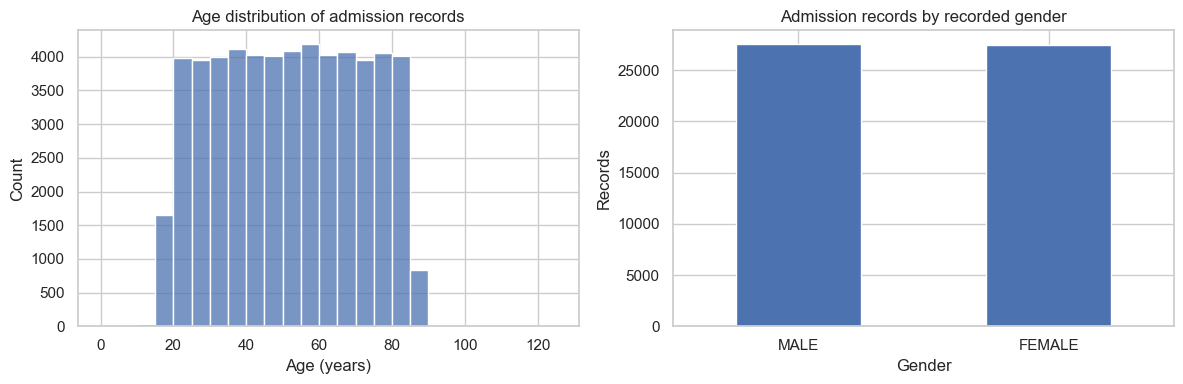

,Records,Share
Medical Condition,,
ARTHRITIS,9218,0.167704
DIABETES,9216,0.167667
HYPERTENSION,9151,0.166485
OBESITY,9146,0.166394
CANCER,9140,0.166285
ASTHMA,9095,0.165466


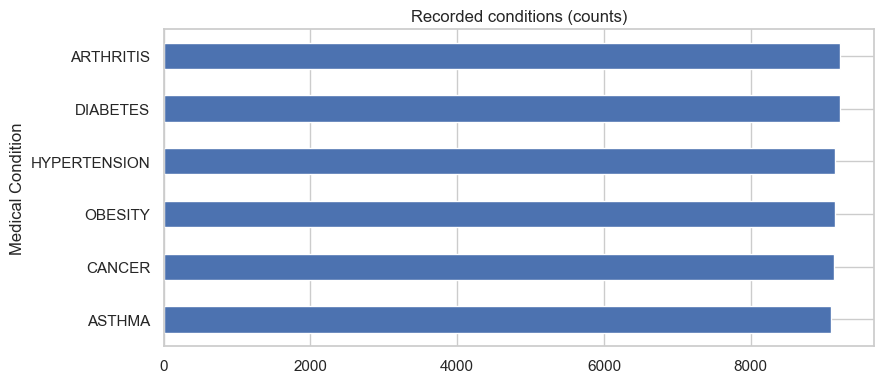

Medical Condition,ARTHRITIS,ASTHMA,CANCER,DIABETES,HYPERTENSION,OBESITY
AgeGroup,,,,,,
0-18,149,150,146,140,143,158
19-35,2262,2266,2271,2219,2234,2267
36-50,2062,1983,1986,2094,2011,2031
51-65,2029,1978,2053,2087,2048,2103
66+,2716,2718,2684,2676,2715,2587


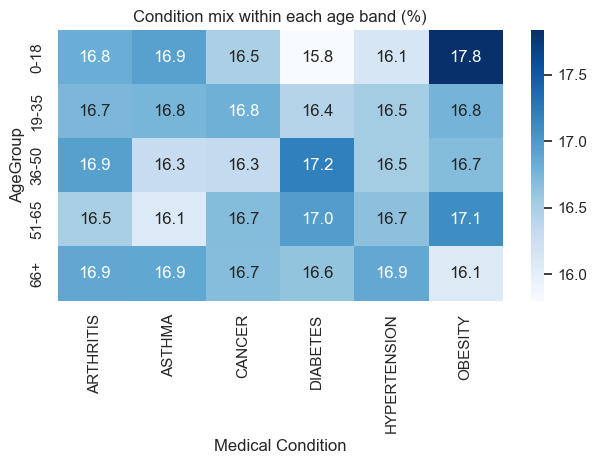

In [6]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.histplot(ops['Age'],bins=np.arange(0,126,5),ax=axes[0])
axes[0].set_title('Age distribution of admission records'); axes[0].set_xlabel('Age (years)')
ops['Gender'].value_counts().plot.bar(ax=axes[1], rot=0)
axes[1].set_title('Admission records by recorded gender'); axes[1].set_ylabel('Records')
savefig('01_demographics')
condition_counts = ops['Medical Condition'].value_counts()
display(condition_counts.to_frame('Records').assign(Share=lambda x:x['Records']/len(ops)))
condition_counts.sort_values().plot.barh(figsize=(9,4),title='Recorded conditions (counts)')
savefig('02_conditions')
age_condition_counts = pd.crosstab(ops['AgeGroup'], ops['Medical Condition'])
age_condition_pct = age_condition_counts.div(age_condition_counts.sum(axis=1),axis=0)*100
display(age_condition_counts)
sns.heatmap(age_condition_pct,annot=True,fmt='.1f',cmap='Blues')
plt.title('Condition mix within each age band (%)');savefig('03_age_condition_mix')

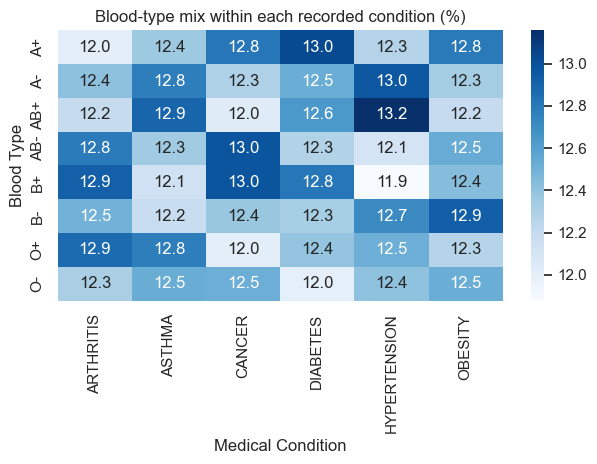

chi_square             34.818083
p_value                 0.476858
cramers_v               0.011256
min_expected_cell    1125.830150
dtype: float64

Report effect size and counts, not just p-value. Synthetic association is not medical evidence.


In [7]:
blood_counts = pd.crosstab(ops['Blood Type'],ops['Medical Condition'])
blood_within_condition = blood_counts.div(blood_counts.sum(axis=0),axis=1)*100
sns.heatmap(blood_within_condition,annot=True,fmt='.1f',cmap='Blues')
plt.title('Blood-type mix within each recorded condition (%)');savefig('04_blood_condition')
chi2,p,dof,expected = chi2_contingency(blood_counts)
n = blood_counts.to_numpy().sum()
cramers_v = np.sqrt(chi2/(n*min(blood_counts.shape[0]-1,blood_counts.shape[1]-1)))
blood_association = {'chi_square':float(chi2),'p_value':float(p),'cramers_v':float(cramers_v),
                     'min_expected_cell':float(expected.min())}
display(pd.Series(blood_association))
print('Report effect size and counts, not just p-value. Synthetic association is not medical evidence.')

## Q3 and Q7 Admissions over time and coverage
Do not sum month names across unequal coverage and call the result seasonality. Calculate chronological year-month records, observed calendar days and admissions per observed day. For comparisons/forecasts exclude the first and last partially covered months unless full coverage is confirmed.

,Records,CalendarDays,ObservedDays,CompleteMonth,RecordsPerObservedDay,YearMonth
2019-05,677,31,24,False,28.208333,2019-05
2019-06,899,30,30,True,29.966667,2019-06
2019-07,951,31,31,True,30.677419,2019-07
2019-08,985,31,31,True,31.774194,2019-08
2019-09,924,30,30,True,30.800000,2019-09
...,...,...,...,...,...,...
2024-01,903,31,31,True,29.129032,2024-01
2024-02,869,29,29,True,29.965517,2024-02
2024-03,902,31,31,True,29.096774,2024-03
2024-04,941,30,30,True,31.366667,2024-04


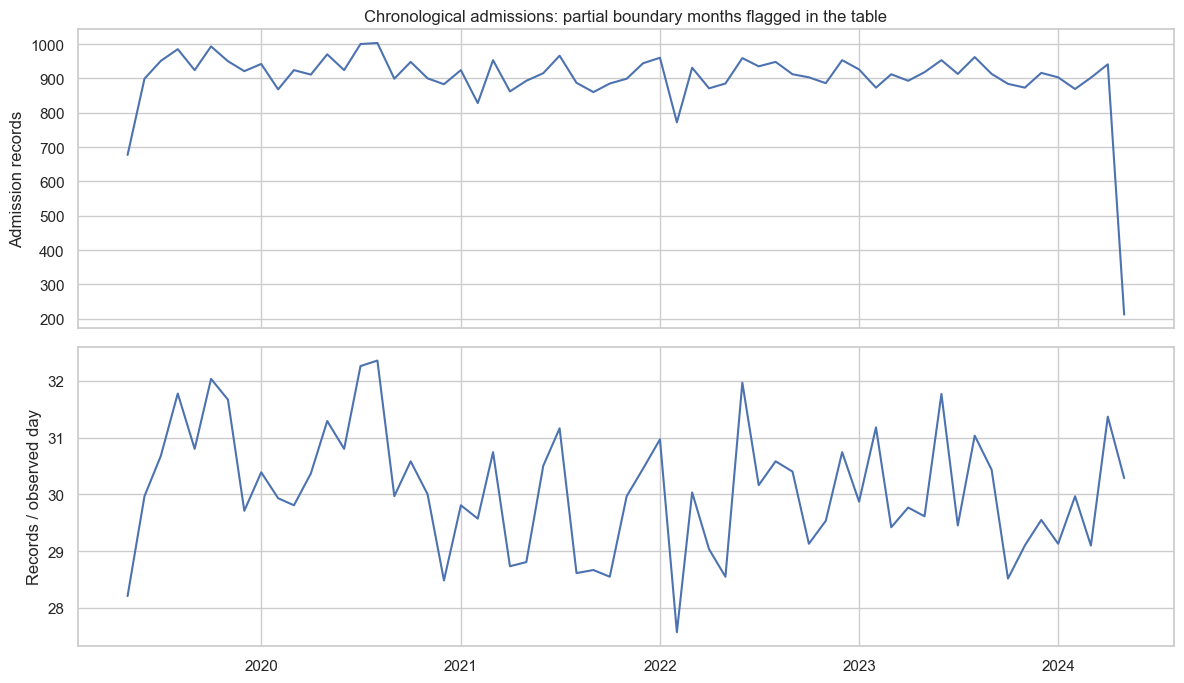

,MeanDailyRecords,CompleteMonths
Month,,
1,30.032258,5
2,29.643596,5
3,29.819355,5
4,29.853333,5
5,29.564516,4
6,31.000000,5
7,30.741935,5
8,30.870968,5
9,30.053333,5


Season screen is descriptive; month length, synthetic generation and limited repetitions affect interpretation.


In [8]:
first_day, last_day = ops['AdmissionDate'].min(),ops['AdmissionDate'].max()
months = pd.period_range(first_day.to_period('M'),last_day.to_period('M'),freq='M')
monthly = pd.DataFrame(index=months)
monthly['Records'] = ops.groupby(ops['AdmissionDate'].dt.to_period('M')).size().reindex(months,fill_value=0)
monthly['CalendarDays'] = monthly.index.days_in_month
monthly['ObservedDays'] = [max(0,(min(p.end_time.normalize(),last_day)-max(p.start_time,first_day)).days+1)
                           for p in months]
monthly['CompleteMonth'] = monthly['ObservedDays'].eq(monthly['CalendarDays'])
monthly['RecordsPerObservedDay'] = monthly['Records']/monthly['ObservedDays']
monthly['YearMonth'] = monthly.index.astype(str)
display(monthly)
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
axes[0].plot(monthly.index.to_timestamp(),monthly['Records']);axes[0].set_ylabel('Admission records')
axes[1].plot(monthly.index.to_timestamp(),monthly['RecordsPerObservedDay']);axes[1].set_ylabel('Records / observed day')
axes[0].set_title('Chronological admissions: partial boundary months flagged in the table')
savefig('05_monthly_admissions')
season_screen = monthly.loc[monthly['CompleteMonth']].assign(Month=lambda x:x.index.month).groupby('Month').agg(
    MeanDailyRecords=('RecordsPerObservedDay','mean'),CompleteMonths=('Records','size'))
display(season_screen)
print('Season screen is descriptive; month length, synthetic generation and limited repetitions affect interpretation.')

,Records,MeanLOS,MedianLOS,StayDays
Admission Type,,,,
ELECTIVE,18473,15.511178,15.0,286538
EMERGENCY,18102,15.584134,16.0,282104
URGENT,18391,15.403839,15.0,283292


,Records,MeanLOS,MedianLOS,P90LOS
Medical Condition,,,,
ARTHRITIS,9218,15.504231,15.0,27.0
ASTHMA,9095,15.677295,16.0,28.0
CANCER,9140,15.501204,15.0,28.0
DIABETES,9216,15.430664,15.0,27.0
HYPERTENSION,9151,15.436236,15.0,27.0
OBESITY,9146,15.447627,15.0,27.0


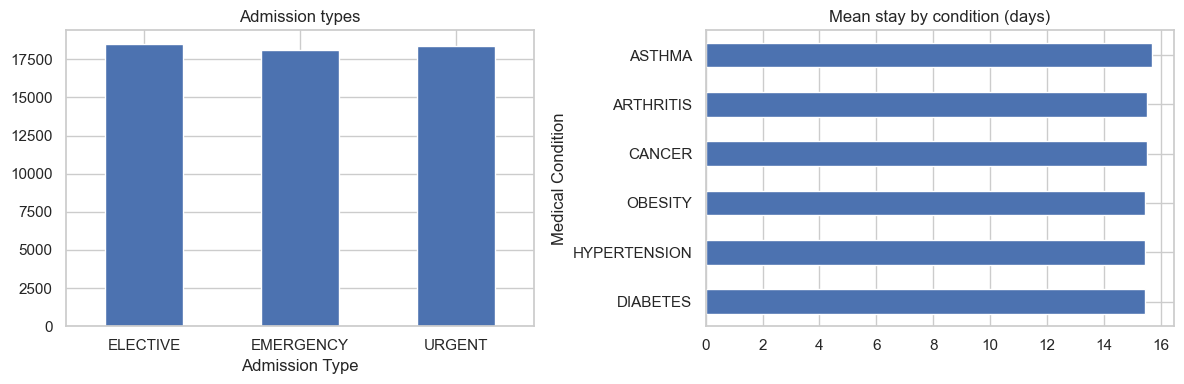

In [9]:
admission_types = ops.groupby('Admission Type').agg(Records=('RecordID','size'),
       MeanLOS=('LOS_Days','mean'),MedianLOS=('LOS_Days','median'),StayDays=('LOS_Days','sum'))
los_conditions = ops.groupby('Medical Condition').agg(Records=('RecordID','size'),
       MeanLOS=('LOS_Days','mean'),MedianLOS=('LOS_Days','median'),P90LOS=('LOS_Days',lambda s:s.quantile(.9)))
display(admission_types);display(los_conditions)
fig,axes=plt.subplots(1,2,figsize=(12,4))
admission_types['Records'].plot.bar(ax=axes[0],rot=0,title='Admission types')
los_conditions['MeanLOS'].sort_values().plot.barh(ax=axes[1],title='Mean stay by condition (days)')
savefig('06_admission_type_los')

## Q4 Billing and insurance
Use the nonnegative-billing view, displaying its record denominator and exclusions. Billing is not revenue received or cost. Small differences between near-balanced categories are not sufficient grounds for clinical or business recommendations.

,Records,TotalBilling,MeanBilling,MedianBilling,P90Billing
Medical Condition,,,,,
DIABETES,9197,2.364947e+08,25714.326349,25681.008034,45156.865687
OBESITY,9127,2.360171e+08,25859.215373,26200.514545,44962.962269
ARTHRITIS,9207,2.351735e+08,25542.898356,25628.302932,45349.199031
HYPERTENSION,9131,2.333869e+08,25559.844868,25337.536074,45417.314244
ASTHMA,9077,2.331462e+08,25685.385020,25684.406728,45237.627110
CANCER,9121,2.299032e+08,25205.924207,24990.114131,44956.536466


,AdmissionRecords
Insurance Provider,
CIGNA,11139
MEDICARE,11039
UNITEDHEALTHCARE,11014
BLUE CROSS,10952
AETNA,10822


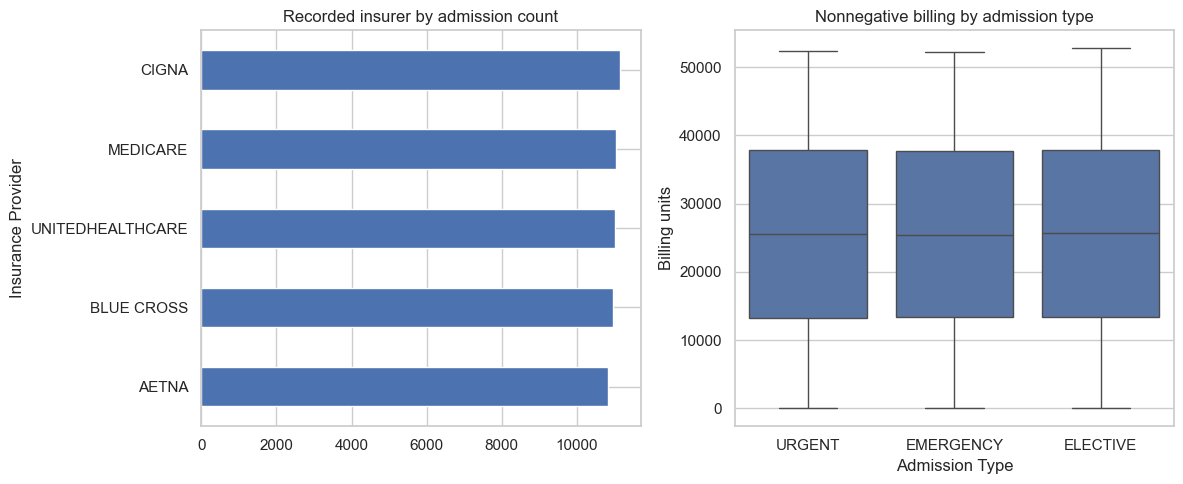

,count,mean,median,std
Admission Type,,,,
ELECTIVE,18437,25663.342261,25706.745499,14187.363355
EMERGENCY,18070,25551.133763,25465.122840,14130.358720
URGENT,18353,25568.439653,25595.593053,14209.523345


In [10]:
billing_by_condition=finance.groupby('Medical Condition').agg(Records=('RecordID','size'),
    TotalBilling=('Billing Amount','sum'),MeanBilling=('Billing Amount','mean'),
    MedianBilling=('Billing Amount','median'),P90Billing=('Billing Amount',lambda s:s.quantile(.9)))
display(billing_by_condition.sort_values('TotalBilling',ascending=False))
insurance=ops.groupby('Insurance Provider').size().sort_values(ascending=False).to_frame('AdmissionRecords')
display(insurance)
fig,axes=plt.subplots(1,2,figsize=(12,5))
insurance['AdmissionRecords'].sort_values().plot.barh(ax=axes[0],title='Recorded insurer by admission count')
sns.boxplot(data=finance,x='Admission Type',y='Billing Amount',ax=axes[1])
axes[1].set_title('Nonnegative billing by admission type');axes[1].set_ylabel('Billing units')
savefig('07_insurance_billing')
display(finance.groupby('Admission Type')['Billing Amount'].agg(['count','mean','median','std']))

## Q5 Provider labels and case volume
The old analysis found about 40,000 distinct labels for hospitals and doctors and very few records per label. Display caseload, not provider performance. Different strings are not verified distinct providers, and equal names are not verified identical providers. Never merge labels by rearranging tokens.

Select top providers by record count, not alphabetic `.head(10)`. Normal-result shares need denominators and uncertainty. A minimum of 30 records is a transparent exploratory display threshold, not a guarantee of reliable clinical comparison. No case-mix-adjusted performance inference is made.

Hospital distinct labels: 39876 single-record labels: 32072


,Records,NormalRecords,MeanLOS,NormalResultShare,WilsonLow,WilsonHigh
Hospital,,,,,,
LLC SMITH,44,14,15.568182,0.318182,0.199991,0.465572
LTD SMITH,39,12,16.512821,0.307692,0.185658,0.464215
JOHNSON PLC,37,9,16.135135,0.243243,0.133612,0.401176
SMITH LTD,37,18,15.135135,0.486486,0.334462,0.641054
SMITH GROUP,36,11,17.000000,0.305556,0.180043,0.468566
SMITH PLC,36,14,17.638889,0.388889,0.247847,0.551358
JOHNSON INC,34,13,14.529412,0.382353,0.239000,0.549593
SMITH INC,33,14,15.393939,0.424242,0.272354,0.591930
GROUP SMITH,32,17,16.312500,0.531250,0.364492,0.691309


Labels with at least 30 records: 12


,Records,NormalRecords,MeanLOS,NormalResultShare,WilsonLow,WilsonHigh
Hospital,,,,,,
LLC SMITH,44,14,15.568182,0.318182,0.199991,0.465572
LTD SMITH,39,12,16.512821,0.307692,0.185658,0.464215
JOHNSON PLC,37,9,16.135135,0.243243,0.133612,0.401176
SMITH LTD,37,18,15.135135,0.486486,0.334462,0.641054
SMITH GROUP,36,11,17.000000,0.305556,0.180043,0.468566
SMITH PLC,36,14,17.638889,0.388889,0.247847,0.551358
JOHNSON INC,34,13,14.529412,0.382353,0.239000,0.549593
SMITH INC,33,14,15.393939,0.424242,0.272354,0.591930
GROUP SMITH,32,17,16.312500,0.531250,0.364492,0.691309


Doctor distinct labels: 40341 single-record labels: 30936


,Records,NormalRecords,MeanLOS,NormalResultShare,WilsonLow,WilsonHigh
Doctor,,,,,,
MICHAEL SMITH,27,6,15.629630,0.222222,0.106071,0.407573
JOHN SMITH,22,9,14.363636,0.409091,0.232556,0.612655
ROBERT SMITH,21,7,13.809524,0.333333,0.171945,0.546269
JAMES SMITH,20,5,17.300000,0.250000,0.111860,0.468705
MICHAEL JOHNSON,20,13,18.700000,0.650000,0.432851,0.818810
ROBERT JOHNSON,19,5,13.789474,0.263158,0.118062,0.487920
DAVID SMITH,19,7,15.315789,0.368421,0.191493,0.589608
MICHAEL WILLIAMS,18,9,15.500000,0.500000,0.290307,0.709693
MATTHEW SMITH,17,11,13.764706,0.647059,0.413000,0.826905


Labels with at least 30 records: 0


,Records,NormalRecords,MeanLOS,NormalResultShare,WilsonLow,WilsonHigh
Doctor,,,,,,


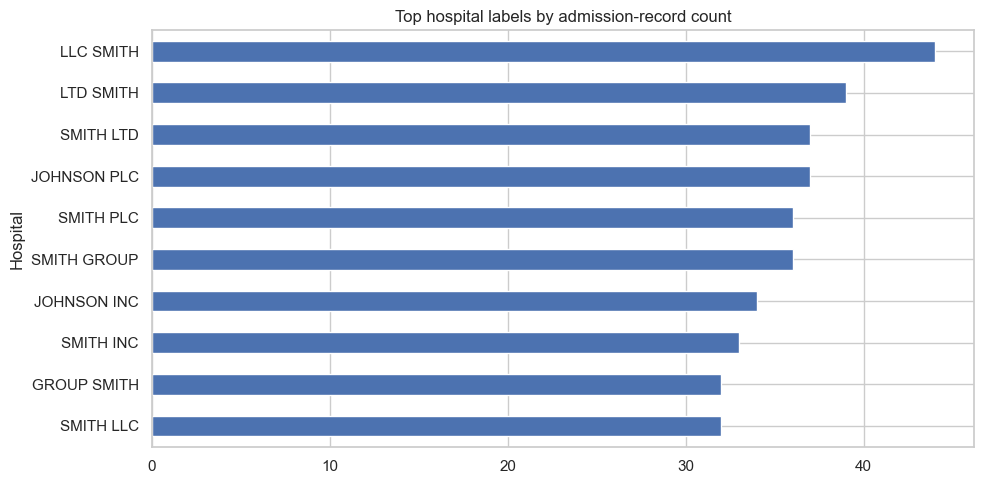

In [11]:
def provider_summary(column):
    d=ops.groupby(column).agg(Records=('RecordID','size'),NormalRecords=('Test Results',lambda s:s.eq('NORMAL').sum()),
                             MeanLOS=('LOS_Days','mean'))
    d['NormalResultShare']=d['NormalRecords']/d['Records']
    z=1.96;n=d['Records'];p=d['NormalResultShare']
    center=(p+z*z/(2*n))/(1+z*z/n)
    half=z*np.sqrt((p*(1-p)+z*z/(4*n))/n)/(1+z*z/n)
    d['WilsonLow']=center-half;d['WilsonHigh']=center+half
    return d.sort_values('Records',ascending=False)
hospitals=provider_summary('Hospital');doctors=provider_summary('Doctor')
for label,d in [('Hospital',hospitals),('Doctor',doctors)]:
    print(label, 'distinct labels:',len(d),'single-record labels:',int(d['Records'].eq(1).sum()))
    display(d.head(10))
    eligible=d.loc[d['Records']>=30]
    print('Labels with at least 30 records:',len(eligible))
    display(eligible.head(10))
hospitals.head(10)['Records'].sort_values().plot.barh(figsize=(10,5),title='Top hospital labels by admission-record count')
savefig('08_provider_volume')

## Q6 Test results and recorded medication labels
Replace recovery-rate terminology with Normal-result share. It is a proportion of recorded test categories, not treatment success. Recorded medications by condition are frequency summaries of synthetic labels, not recommended treatments.

,Records,Share
Test Results,,
ABNORMAL,18437,0.335426
NORMAL,18331,0.333497
INCONCLUSIVE,18198,0.331077


,Records,NormalRecords,NormalResultShare
Medical Condition,,,
ASTHMA,9095,3116,0.342606
HYPERTENSION,9151,3106,0.339416
DIABETES,9216,3061,0.332140
OBESITY,9146,3030,0.331292
CANCER,9140,3018,0.330197
ARTHRITIS,9218,3000,0.325450


Medication,ASPIRIN,IBUPROFEN,LIPITOR,PARACETAMOL,PENICILLIN
Medical Condition,,,,,
ARTHRITIS,1901,1805,1810,1858,1844
ASTHMA,1781,1802,1814,1870,1828
CANCER,1768,1862,1904,1829,1777
DIABETES,1836,1846,1875,1794,1865
HYPERTENSION,1845,1874,1823,1839,1770
OBESITY,1853,1834,1812,1775,1872


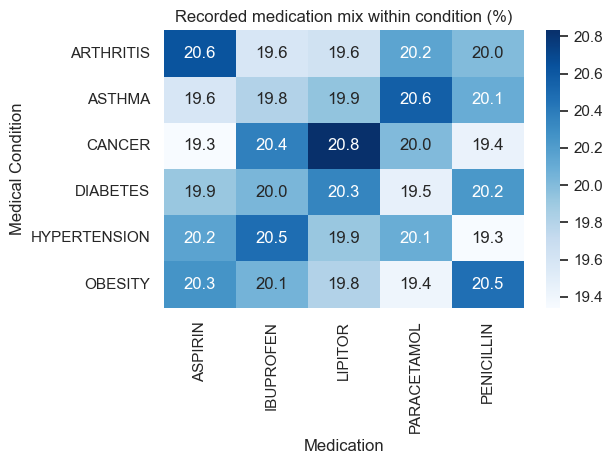

Most frequent recorded medication labels (ties may exist):


Medical Condition
ARTHRITIS           ASPIRIN
ASTHMA          PARACETAMOL
CANCER              LIPITOR
DIABETES            LIPITOR
HYPERTENSION      IBUPROFEN
OBESITY          PENICILLIN
dtype: string

In [12]:
test_counts=ops['Test Results'].value_counts()
display(test_counts.to_frame('Records').assign(Share=lambda x:x['Records']/len(ops)))
normal_by_condition=ops.groupby('Medical Condition').agg(Records=('RecordID','size'),
                     NormalRecords=('Test Results',lambda s:s.eq('NORMAL').sum()))
normal_by_condition['NormalResultShare']=normal_by_condition['NormalRecords']/normal_by_condition['Records']
display(normal_by_condition.sort_values('NormalResultShare',ascending=False))
med_counts=pd.crosstab(ops['Medical Condition'],ops['Medication'])
display(med_counts)
sns.heatmap(med_counts.div(med_counts.sum(axis=1),axis=0)*100,annot=True,fmt='.1f',cmap='Blues')
plt.title('Recorded medication mix within condition (%)');savefig('09_medication_mix')
print('Most frequent recorded medication labels (ties may exist):')
display(med_counts.idxmax(axis=1))

## Q7 Resource proxies and room labels
Sum stay duration to quantify recorded stay-days by cohort; this is not observed nursing time or available-bed utilisation. Stay-days are assigned to the admission cohort even when the stay crosses months. Room Number alone is not a unique room across hospitals or an ordinal measure of room quality.

In [13]:
resources=ops.groupby(['AgeGroup','Medical Condition','Admission Type'],observed=True).agg(
    Records=('RecordID','size'),StayDays=('LOS_Days','sum'),MeanLOS=('LOS_Days','mean'))
resources['StayDaysShare']=resources['StayDays']/resources['StayDays'].sum()
display(resources.sort_values('StayDays',ascending=False).head(15))
room_groups=ops.groupby(['Hospital','Room Number']).agg(Records=('RecordID','size'),
                     NormalRecords=('Test Results',lambda s:s.eq('NORMAL').sum()))
room_groups['NormalResultShare']=room_groups['NormalRecords']/room_groups['Records']
room_eligible=room_groups.loc[room_groups['Records']>=30]
print('Hospital-room pairs with at least 30 records:',len(room_eligible))
display(room_eligible.sort_values('Records',ascending=False).head(10))
print('No eligible groups is a legitimate result: room-outcome comparison is then unsupported.')

Records  StayDays    MeanLOS  \
AgeGroup Medical Condition Admission Type                                 
66+      CANCER            EMERGENCY           916     14864  16.227074   
         ARTHRITIS         URGENT              946     14811  15.656448   
         HYPERTENSION      URGENT              931     14345  15.408163   
                           ELECTIVE            930     14334  15.412903   
         ARTHRITIS         EMERGENCY           915     14326  15.656831   
         ASTHMA            URGENT              915     14293  15.620765   
         DIABETES          URGENT              930     14197  15.265591   
         ASTHMA            EMERGENCY           908     14051  15.474670   
         OBESITY           ELECTIVE            866     13944  16.101617   
                           EMERGENCY           889     13883  15.616423   
         ASTHMA            ELECTIVE            895     13852  15.477095   
         CANCER            ELECTIVE            901     13782  15.296337   
                           URGENT              867     13700  15.801615   
         ARTHRITIS         ELECTIVE            855     13685  16.005848   
         DIABETES          ELECTIVE            869     13503  15.538550   

                                           StayDaysShare  
AgeGroup Medical Condition Admission Type                 
66+      CANCER            EMERGENCY            0.017447  
         ARTHRITIS         URGENT               0.017385  
         HYPERTENSION      URGENT               0.016838  
                           ELECTIVE             0.016825  
         ARTHRITIS         EMERGENCY            0.016816  
         ASTHMA            URGENT               0.016777  
         DIABETES          URGENT               0.016664  
         ASTHMA            EMERGENCY            0.016493  
         OBESITY           ELECTIVE             0.016367  
                           EMERGENCY            0.016296  
         ASTHMA            ELECTIVE             0.016259  
         CANCER            ELECTIVE             0.016177  
                           URGENT               0.016081  
         ARTHRITIS         ELECTIVE             0.016063  
         DIABETES          ELECTIVE             0.015850

Hospital-room pairs with at least 30 records: 0


,,Records,NormalRecords,NormalResultShare
Hospital,Room Number,,,


No eligible groups is a legitimate result: room-outcome comparison is then unsupported.


### Illustrative recorded-stay census
Count concurrent recorded stays using the interval [admission date, discharge date), so discharge day is excluded. This is a date-only overnight-style proxy with no bed capacity denominator. It assumes each retained record is a separate stay; no actual patient identities are verified.

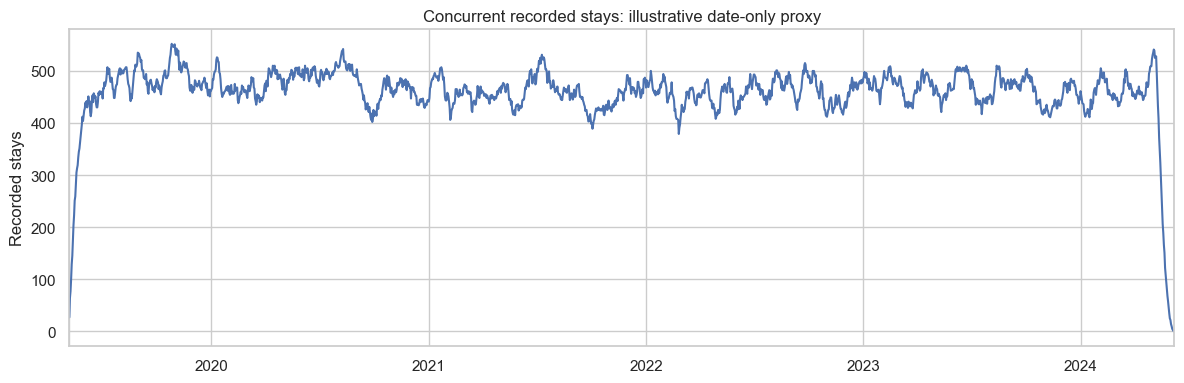

In [14]:
events=pd.concat([ops.groupby('AdmissionDate').size(),-ops.groupby('DischargeDate').size()]).groupby(level=0).sum()
census_index=pd.date_range(ops['AdmissionDate'].min(),ops['DischargeDate'].max(),freq='D')
census=events.reindex(census_index,fill_value=0).cumsum().to_frame('RecordedStayCensusProxy')
assert census['RecordedStayCensusProxy'].ge(0).all()
assert int(census['RecordedStayCensusProxy'].sum())==int(ops['LOS_Days'].sum())
census.plot(figsize=(12,4),legend=False,title='Concurrent recorded stays: illustrative date-only proxy')
plt.ylabel('Recorded stays');savefig('10_recorded_stay_census')

## Q8 Predictive feasibility before modelling
No patient ID means future frequent-admission risk cannot be assessed from names. No department field means department-load forecasts cannot be produced. Actual staff/bed/medication requirements are unavailable; only scenarios using stay-days and recorded labels can be demonstrated.

Evaluate monthly admissions, admission-time billing and length of stay against simple baselines. A model that fails to improve on a baseline is a valid finding. Do not infer useful drivers from feature importance in a model with weak generalisation. All predictive experiments use synthetic records, not clinical deployment.

### Admissions projection with chronological backtesting
Use only complete months. For each of the last six complete months, fit on earlier months and predict the next month. Compare trailing-12-month mean daily rate with a linear daily-rate trend; convert predicted rates to counts using the target month's calendar days. The final three-month projection starts after the last complete historical month, not after today's date. It may overlap the partially observed boundary month.

,YearMonth,Actual,Baseline,LinearTrend
0,2023-11,873,903.309332,890.072730
1,2023-12,916,932.300198,917.878874
2,2024-01,903,929.216865,917.150444
3,2024-02,869,867.474379,856.476882
4,2024-03,902,924.166475,915.861633
5,2024-04,941,893.548202,884.814106


,Model,MAE,RMSE
0,Baseline,23.995048,27.739951
1,LinearTrend,19.278782,25.823346


One short rolling holdout does not establish stable forecast skill. Do not tune on these evaluation months.


,YearMonth,BaselineProjection,LinearTrendProjection,Status
0,2024-05,927.466475,917.622044,HISTORICAL-ORIGIN EDUCATIONAL PROJECTION; NOT ...
1,2024-06,897.548202,887.514577,HISTORICAL-ORIGIN EDUCATIONAL PROJECTION; NOT ...
2,2024-07,927.466475,916.574748,HISTORICAL-ORIGIN EDUCATIONAL PROJECTION; NOT ...


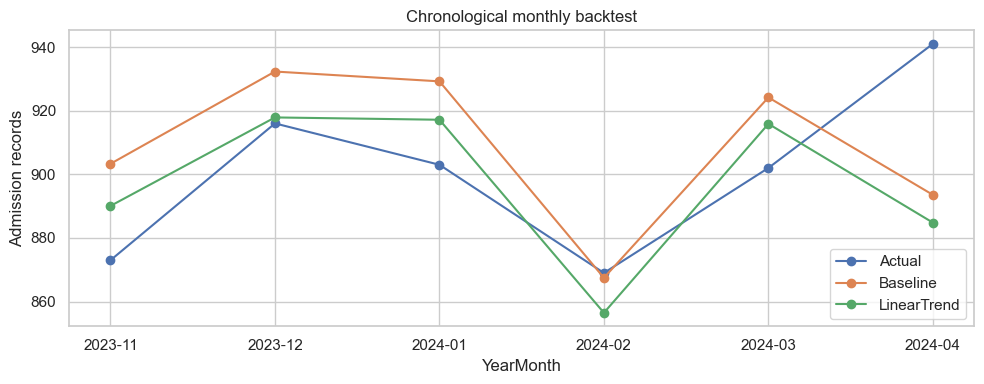

In [15]:
complete=monthly.loc[monthly['CompleteMonth']].copy()
if len(complete)<24: raise ValueError('Need at least 24 complete months for this demonstration.')
backtest=[]
for i in range(len(complete)-6,len(complete)):
    hist=complete.iloc[:i];actual=complete.iloc[i]
    rate_mean=hist['RecordsPerObservedDay'].tail(12).mean()
    trend=LinearRegression().fit(np.arange(len(hist)).reshape(-1,1),hist['RecordsPerObservedDay'])
    rate_trend=max(0,float(trend.predict([[len(hist)]])[0]))
    backtest.append({'YearMonth':complete.index[i].strftime('%Y-%m'),'Actual':actual['Records'],
                     'Baseline':rate_mean*actual['CalendarDays'],'LinearTrend':rate_trend*actual['CalendarDays']})
backtest=pd.DataFrame(backtest)
forecast_metrics=pd.DataFrame([{'Model':name,'MAE':mean_absolute_error(backtest['Actual'],backtest[name]),
    'RMSE':np.sqrt(mean_squared_error(backtest['Actual'],backtest[name]))} for name in ['Baseline','LinearTrend']])
display(backtest);display(forecast_metrics)
print('One short rolling holdout does not establish stable forecast skill. Do not tune on these evaluation months.')
future_months=pd.period_range(complete.index[-1]+1,periods=3,freq='M')
final_trend=LinearRegression().fit(np.arange(len(complete)).reshape(-1,1),complete['RecordsPerObservedDay'])
projection=pd.DataFrame({'YearMonth':future_months.astype(str),
 'BaselineProjection':complete['RecordsPerObservedDay'].tail(12).mean()*future_months.days_in_month,
 'LinearTrendProjection':np.maximum(0,final_trend.predict(np.arange(len(complete),len(complete)+3).reshape(-1,1)))*future_months.days_in_month})
projection['Status']='HISTORICAL-ORIGIN EDUCATIONAL PROJECTION; NOT CURRENT DEMAND'
display(projection)
backtest.set_index('YearMonth')[['Actual','Baseline','LinearTrend']].plot(figsize=(10,4),marker='o')
plt.title('Chronological monthly backtest');plt.ylabel('Admission records');savefig('11_forecast_backtest')

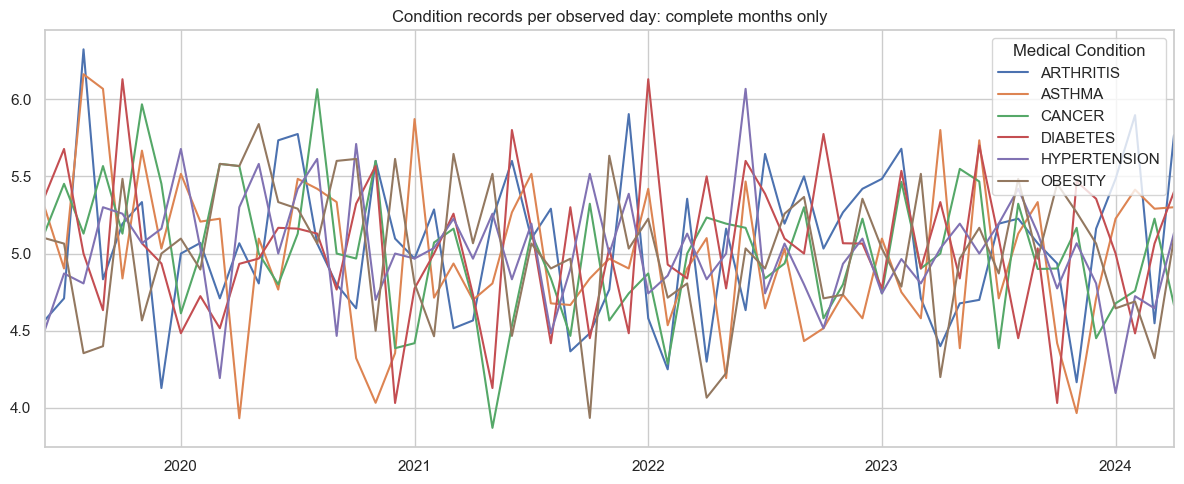

Historical lines alone do not establish which condition will increase. Condition-specific forecasting would need separate holdout validation.


In [16]:
condition_monthly=pd.crosstab(ops['AdmissionDate'].dt.to_period('M'),ops['Medical Condition']).reindex(months,fill_value=0)
condition_rates=condition_monthly.div(monthly['ObservedDays'],axis=0)
condition_rates.loc[monthly['CompleteMonth']].plot(figsize=(12,5))
plt.title('Condition records per observed day: complete months only');savefig('12_condition_time')
print('Historical lines alone do not establish which condition will increase. Condition-specific forecasting would need separate holdout validation.')

### Admission-time feature contract and chronological split
Predictors: age, gender, recorded condition, admission type and insurance provider. These are assumed available at admission for this educational exercise. Exclude LOS, discharge date, test results and medications because availability at prediction time is not established. Exclude names, hospital/doctor labels, room identifiers, BillingBand and HighBillingDescriptive.

Use the earliest 60% of unique admission dates for training, next 20% for validation and final 20% for test. Same-day records stay in the same partition. Preprocessing is fit on training only. Patient-level separation is impossible without verified identity; residual duplicated/near-duplicated synthetic records are a limitation.

In [17]:
model_data=finance.sort_values(['AdmissionDate','RecordID']).copy()
unique_dates=np.sort(model_data['AdmissionDate'].unique())
cut1=pd.Timestamp(unique_dates[int(len(unique_dates)*.6)])
cut2=pd.Timestamp(unique_dates[int(len(unique_dates)*.8)])
train=model_data.loc[model_data['AdmissionDate']<cut1]
valid=model_data.loc[(model_data['AdmissionDate']>=cut1)&(model_data['AdmissionDate']<cut2)]
test=model_data.loc[model_data['AdmissionDate']>=cut2]
assert len(train)>0 and len(valid)>0 and len(test)>0
assert train['AdmissionDate'].max()<valid['AdmissionDate'].min()<test['AdmissionDate'].min()
features=['Age','Gender','Medical Condition','Admission Type','Insurance Provider']
num=['Age'];cat=[x for x in features if x not in num]
def preprocessing():
    return ColumnTransformer([
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),
        ('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                                ('encode',OneHotEncoder(handle_unknown='ignore'))]),cat)])
print('Training/validation/test records:',len(train),len(valid),len(test))
print('Admission date cutoffs:',cut1,cut2)

Training/validation/test records: 32978 10954 10928
Admission date cutoffs: 2022-05-08 00:00:00 2023-05-08 00:00:00


### Billing amount and length-of-stay regression
Compare fixed Ridge pipelines with training-mean DummyRegressor baselines. Report MAE, RMSE and R-squared on validation and test. These are continuous-value tasks, distinct from the high-billing classification below. LOS evaluation here uses the same nonnegative-billing cohort; disclose that restriction.

In [18]:
regression_results=[];reg_predictions=[]
for target in ['Billing Amount','LOS_Days']:
    models={'TrainingMean':DummyRegressor(strategy='mean'),
            'Ridge':Pipeline([('prep',preprocessing()),('model',Ridge(alpha=10,solver='lsqr'))])}
    for name,model in models.items():
        model.fit(train[features],train[target])
        for split_name,part in [('Validation',valid),('Test',test)]:
            pred=model.predict(part[features])
            regression_results.append({'Target':target,'Model':name,'Split':split_name,
              'MAE':mean_absolute_error(part[target],pred),'RMSE':np.sqrt(mean_squared_error(part[target],pred)),
              'R2':r2_score(part[target],pred)})
            if split_name=='Test':
                reg_predictions.append(pd.DataFrame({'RecordID':part['RecordID'].to_numpy(),
                 'Target':target,'Model':name,'Actual':part[target].to_numpy(),'Prediction':pred}))
regression_results=pd.DataFrame(regression_results)
display(regression_results)
print('A small positive R2 alone is not a deployment case. Compare baseline errors and validation/test stability.')

,Target,Model,Split,MAE,RMSE,R2
0,Billing Amount,TrainingMean,Validation,12171.837575,14094.934565,-0.000089
1,Billing Amount,TrainingMean,Test,12242.232334,14152.736130,-0.000014
2,Billing Amount,Ridge,Validation,12178.599143,14104.349760,-0.001426
3,Billing Amount,Ridge,Test,12243.301945,14157.978688,-0.000755
4,LOS_Days,TrainingMean,Validation,7.480754,8.632280,-0.000026
5,LOS_Days,TrainingMean,Test,7.629347,8.769432,-0.000055
6,LOS_Days,Ridge,Validation,7.478737,8.631798,0.000086
7,LOS_Days,Ridge,Test,7.631200,8.773509,-0.000985


A small positive R2 alone is not a deployment case. Compare baseline errors and validation/test stability.


### Experimental high-billing classification
Define high billing as recorded amount above the TRAINING 75th percentile. Keep that threshold fixed for validation/test. This target differs from the descriptive full-population flag exported for dashboard exploration. Fit a training-prevalence baseline and an untuned logistic regression pipeline. Report ROC AUC, average precision, Brier score and precision/recall at 0.5. High accuracy can simply reflect the majority class.

In [19]:
training_threshold=float(train['Billing Amount'].quantile(.75))
y_train=train['Billing Amount'].gt(training_threshold).astype(int)
if y_train.nunique()!=2: raise ValueError('Classification requires both target classes.')
class_models={'TrainingPrevalence':DummyClassifier(strategy='prior'),
              'Logistic':Pipeline([('prep',preprocessing()),
                                  ('model',LogisticRegression(max_iter=1000,random_state=SEED))])}
classification_results=[];classification_predictions=[]
for name,model in class_models.items():
    model.fit(train[features],y_train)
    for split_name,part in [('Validation',valid),('Test',test)]:
        y=part['Billing Amount'].gt(training_threshold).astype(int)
        prob=model.predict_proba(part[features])[:,1]
        pred=(prob>=.5).astype(int)
        classification_results.append({'Model':name,'Split':split_name,'HighBillingPrevalence':float(y.mean()),
            'ROC_AUC':roc_auc_score(y,prob) if y.nunique()==2 else np.nan,
            'AveragePrecision':average_precision_score(y,prob) if y.sum()>0 else np.nan,
            'Brier':brier_score_loss(y,prob),'Precision_0.5':precision_score(y,pred,zero_division=0),
            'Recall_0.5':recall_score(y,pred,zero_division=0)})
        if split_name=='Test':
            classification_predictions.append(pd.DataFrame({'RecordID':part['RecordID'].to_numpy(),
             'Model':name,'ActualHighBilling':y.to_numpy(),'ExperimentalProbability':prob}))
classification_results=pd.DataFrame(classification_results)
display(classification_results)
print('Training-only high-billing threshold:',training_threshold)
print('No individual clinical/financial risk claim is justified by this synthetic experiment.')

,Model,Split,HighBillingPrevalence,ROC_AUC,AveragePrecision,Brier,Precision_0.5,Recall_0.5
0,TrainingPrevalence,Validation,0.244842,0.500000,0.244842,0.184921,0.0,0.0
1,TrainingPrevalence,Test,0.245882,0.500000,0.245882,0.185441,0.0,0.0
2,Logistic,Validation,0.244842,0.499686,0.243965,0.184976,0.0,0.0
3,Logistic,Test,0.245882,0.500090,0.245971,0.185516,0.0,0.0


Training-only high-billing threshold: 37933.27274736842
No individual clinical/financial risk claim is justified by this synthetic experiment.


## Answerability register for all brief questions
Not every requested question can be answered by this source. An unsupported question is documented with the missing evidence, not filled with an invented result. “Recovery” is replaced with the directly recorded test-result share. “Most care resources” is restricted to record count and stay-day proxies.

In [21]:
coverage_rows=[
('1a','Age distribution','Descriptive','Age histogram and corrected age groups'),
('1b','Gender distribution','Descriptive','Admission-record counts; not unique people'),
('1c','Blood types within conditions','Descriptive','Within-condition percentages and counts'),
('2a','Most common conditions','Descriptive','Condition counts; not prevalence'),
('2b','Conditions by age','Descriptive','Counts plus within-age mix'),
('2c','Blood type-condition association','Exploratory','Chi-square and Cramers V; synthetic-only'),
('3a','Admissions over time','Descriptive','Year-month counts and observed-day rates'),
('3b','Most common admission type','Descriptive','Counts and shares'),
('3c','LOS by condition/type','Descriptive','Mean, median and denominators'),
('4a','Billing by condition','Descriptive','Nonnegative amounts and eligible-record counts'),
('4b','Insurer record count','Descriptive','Admission-record count, not unique patients'),
('4c','Admission type and billing','Descriptive','Distribution summaries, not causal effect'),
('5a','Highest hospital caseload','Descriptive','Top labels by count; identity unverified'),
('5b','Highest doctor caseload','Descriptive','Top labels by count; identity unverified'),
('5c','Provider outcome differences','Restricted','Normal-result shares, count screen and intervals; not quality'),
('6a','Test-result distribution','Descriptive','Recorded categories'),
('6b','Highest recovery rate','Not available as worded','Normal-result share reported; no recovery variable'),
('6c','Medication per condition','Descriptive','Frequency of synthetic labels, no prescribing advice'),
('7a','Peak periods','Descriptive','Chronological counts and complete-month/day comparisons'),
('7b','Groups needing most resources','Proxy only','Record counts/stay-days; no nursing or cost intensity'),
('7c','Room allocation and outcomes','Restricted','Hospital-room groups; no causal or ordinal room-number claim'),
('8a','Projected admissions','Experimental','Six-month rolling backtest vs baseline; historical-origin projection'),
('8b','Conditions likely to increase','Not established','Historical rates; separate condition forecast validation required'),
('8c','Frequent future admission risk','Not available','No verified patient identifier or longitudinal outcomes'),
('8d','Longer future stays','Experimental','Admission-time LOS regression vs training-mean baseline'),
('8e','Early high billing indicators','Experimental','Training-threshold classifier and billing regression, baseline comparison'),
('8f','Future hospital/department loads','Not established','Sparse/unverified provider labels; no department field'),
('8g','Resource planning','Illustrative','Stay-day/census scenarios; no actual capacity or medication-dose data')]
coverage=pd.DataFrame(coverage_rows,columns=['Question','RequestedAnalysis','Status','EvidenceOrLimitation'])
display(coverage)
coverage.to_csv(OUT/'question_coverage.csv',index=False)

,Question,RequestedAnalysis,Status,EvidenceOrLimitation
0,1a,Age distribution,Descriptive,Age histogram and corrected age groups
1,1b,Gender distribution,Descriptive,Admission-record counts; not unique people
2,1c,Blood types within conditions,Descriptive,Within-condition percentages and counts
3,2a,Most common conditions,Descriptive,Condition counts; not prevalence
4,2b,Conditions by age,Descriptive,Counts plus within-age mix
5,2c,Blood type-condition association,Exploratory,Chi-square and Cramers V; synthetic-only
6,3a,Admissions over time,Descriptive,Year-month counts and observed-day rates
7,3b,Most common admission type,Descriptive,Counts and shares
8,3c,LOS by condition/type,Descriptive,"Mean, median and denominators"
9,4a,Billing by condition,Descriptive,Nonnegative amounts and eligible-record counts


## Exports and generated evidence summary
No copied Version 1 totals are claimed as revised results. Review the generated audit and metrics before updating Power BI or writing final recommendations. The public fact export omits Name and encodes RecordID as a record key only. Raw names are never used for repeated-admission risk.

In [23]:
public=ops.drop(columns=['Name']).copy()
public['AgeGroup']=public['AgeGroup'].astype('string')
public.to_csv(OUT/'healthcare_records_v2.csv',index=False)
finance.drop(columns=['Name']).to_csv(OUT/'billing_nonnegative_v2.csv',index=False)
quarantine.drop(columns=['Name']).to_csv(OUT/'quarantine_records.csv',index=False)
monthly.to_csv(OUT/'monthly_admissions_v2.csv',index=False)
backtest.to_csv(OUT/'admission_forecast_backtest.csv',index=False)
forecast_metrics.to_csv(OUT/'forecast_metrics.csv',index=False)
projection.to_csv(OUT/'historical_origin_projection.csv',index=False)
regression_results.to_csv(OUT/'regression_metrics.csv',index=False)
classification_results.to_csv(OUT/'classification_metrics.csv',index=False)
pd.concat(reg_predictions,ignore_index=True).to_csv(OUT/'heldout_regression_predictions.csv',index=False)
pd.concat(classification_predictions,ignore_index=True).to_csv(OUT/'heldout_classification_predictions.csv',index=False)
for name,frame in [('condition_billing',billing_by_condition),('provider_hospitals',hospitals),
                   ('provider_doctors',doctors),('normal_results_by_condition',normal_by_condition),
                   ('resource_proxies',resources),('medication_counts',med_counts),('recorded_stay_census',census)]:
    frame.to_csv(OUT/f'{name}.csv')
source_manifest.update({'snapshot':snapshot,'training_billing_threshold':training_threshold,
                        'train_cutoff':str(cut1.date()),'test_cutoff':str(cut2.date()),
                        'blood_association':blood_association})
(DOC/'run_manifest.json').write_text(json.dumps(source_manifest,indent=2))
summary=[ '# Healthcare analysis evidence summary',
'Generated from the executed notebook. Synthetic records only; no unique-patient, recovery or deployment claims.',
'## Cleaning and population', audit.to_frame('Count').to_string(),
'Operational records: '+str(len(ops))+'; financial records: '+str(len(finance)),
'## Demographics and conditions',ops['AgeGroup'].value_counts().to_string(),ops['Gender'].value_counts().to_string(),condition_counts.to_string(),
'## Admissions and stay',admission_types.to_string(),los_conditions.to_string(),
'## Billing and insurers',billing_by_condition.to_string(),insurance.to_string(),
'## Test results and medication labels',normal_by_condition.to_string(),med_counts.to_string(),
'## Resources',resources.sort_values('StayDays',ascending=False).head(10).to_string(),
'## Forecast evaluation',forecast_metrics.to_string(index=False),
'## Regression evaluation',regression_results.to_string(index=False),
'## Classification evaluation',classification_results.to_string(index=False),
'## Answerability',coverage.to_string(index=False),
'## Conclusion rules','Claim predictor/forecast skill only if validation and test errors improve materially on baselines. Do not turn random/synthetic differences into real resource or treatment recommendations. Names cannot establish frequent admission risk; Normal is not recovery.' ]
(DOC/'executed_evidence_summary.md').write_text('\n\n'.join(summary))
print('Exported revised data, figures, audit, metrics and evidence summary.')

Exported revised data, figures, audit, metrics and evidence summary.
